# 1 · From A Straight Line To A Tree

<a href="https://colab.research.google.com/github/FH-Prevail/steyr_course/blob/main/notebooks/1_line_to_tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Advanced Data Analysis Techniques · Session 4: Forecasting With Tree-Based Models · Sina Mirshahi, FH OÖ Steyr*


**Hands-on 1.** One product, ice tea, and two ways to describe it: the straight line you know from session 2, and a decision tree. You will

- look at the data and see how ice tea reacts to the temperature,
- fit the straight line and find where it goes wrong,
- grow your first decision tree and read its rules,
- test both on 2025, a year they have never seen, and find out how deep a tree should grow.


**How to work with this notebook**

1. In Colab choose **File, Save a copy in Drive**. Your copy keeps your changes; this original never changes.
2. Run the cells from the top with **Shift + Enter**, or all at once with **Runtime, Run all**.
3. Read the result under each cell before you go on. You do not need to write code from scratch.

| Label | Meaning |
|---|---|
| `# EDIT` | a setting you may change, then run the cell again |
| `# CHECK` | the result for the unchanged course data; after an EDIT the numbers change, and that is fine |
| **Ask an AI** | a prompt that writes the same code in Gemini, ChatGPT or Claude, and how to check its answer |
| **Your answer** | a few words of your own: double-click the cell, write, then Shift + Enter |

The data is synthetic: a drinks wholesaler in Upper Austria, built to look like real weekly sales. No company data is contained.

In [1]:
# Start here: run this cell first. It loads the course data (one small table) and sets up the charts.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = "https://raw.githubusercontent.com/FH-Prevail/steyr_course/main/data"   # the course data on GitHub
if Path("data/drinks_weekly.csv").exists():      # a copy next to the notebook (Google Drive or upload) is used first
    DATA = "data"
sales = pd.read_csv(f"{DATA}/drinks_weekly.csv", parse_dates=["week_start"])
sales["product"] = sales["product"].astype(object)   # plain text labels: the regression formula works with every pandas version

# one colour per method, the same as on the slides
COLOURS = {"Actual sales": "#262626", "Repeat last year": "#E66A1F", "Linear regression": "#1B9E5A",
           "Decision tree": "#7A5C00", "Random forest": "#D04F95", "LightGBM": "#0B5CAD"}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:,.1f}".format)
print("Ready:", len(sales), "rows,", sales["product"].nunique(), "products, weeks from",
      sales["week_start"].min().date(), "to", sales["week_start"].max().date())
# CHECK: Ready: 1672 rows, 8 products, weeks from 2022-01-03 to 2025-12-29

Ready: 1672 rows, 8 products, weeks from 2022-01-03 to 2025-12-29


> **Ask an AI · the context first.** In ChatGPT or Claude, paste this before any prompt of this notebook (Gemini in Colab already sees the notebook):
>
> *"I work in Google Colab with pandas, scikit-learn, statsmodels and LightGBM. My table `sales` has one row per product and week: `week_start` (the Monday), `product` (8 drinks), `units` (cases sold, the target), `pallets` (pallets picked in the warehouse, known only after the week), `temp_forecast` (the weather forecast for the week, mean daily maximum in °C), `temp_actual` (the weather that came, known only after the week), `discount_pct` (the planned promotion discount, 0 = none) and `holiday_days` (public holidays from Monday to Friday). We plan on Sunday evening for the coming week. Keep the code short and commented, and never use information that is unknown on that Sunday."*
>
> **Check every answer:** run it, compare with the `# CHECK` line, and make sure you can say what each line does. Share only course data with an AI tool, never company data.

## 1. The data

One row is one product in one week: 8 products × 209 weeks = 1672 rows. We plan on **Sunday evening** for the week that starts on Monday, so the last column says what we know at that moment.

| Column | What it is | Known on Sunday evening? |
|---|---|---|
| `week_start` | the Monday of the week | yes |
| `product` | one of eight drinks | yes |
| `units` | cases sold in the week: **the number we forecast** (the target) | no, it is the answer |
| `pallets` | pallets picked in the warehouse for these cases | no, only after the week |
| `temp_forecast` | the weather forecast for the week: mean of the daily maximum, °C | yes |
| `temp_actual` | the weather that came | no, only after the week |
| `discount_pct` | the planned promotion discount, 0 = no promotion | yes, promotions are planned |
| `holiday_days` | public holidays from Monday to Friday | yes |

In [2]:
sales.head(8)

,week_start,product,units,pallets,temp_forecast,temp_actual,discount_pct,holiday_days
0,2022-01-03,Mineral water,1519,19.0,3.5,2.6,0,1
1,2022-01-10,Mineral water,1704,21.3,0.2,0.1,0,0
2,2022-01-17,Mineral water,1730,21.6,1.4,2.1,0,0
3,2022-01-24,Mineral water,1513,18.9,-2.8,-3.3,0,0
4,2022-01-31,Mineral water,1616,20.2,5.6,4.4,0,0
5,2022-02-07,Mineral water,2677,33.5,4.5,6.0,30,0
6,2022-02-14,Mineral water,1501,18.8,4.4,4.3,0,0
7,2022-02-21,Mineral water,1680,21.0,4.1,4.0,0,0


In [3]:
sales.groupby("product")["units"].agg(["mean", "min", "max"]).round(0).astype(int)
# CHECK: Mineral water sells about 2,399 cases in an average week

,mean,min,max
product,,,
Apple spritzer,827,422,2998
Energy drink,300,86,1106
Ice tea,669,148,3948
Lager beer,1635,935,5039
Mineral water,2399,1261,8714
Mulled wine,115,0,1408
Orange juice,574,365,1190
Radler,453,45,2695


**What to see.** The eight products live on very different scales: mineral water sells about 2,399 cases in an average week, mulled wine about 115, but up to 1,408 in a week of its season.

## 2. Look before you model

A model can only find what is in the data. Look first.

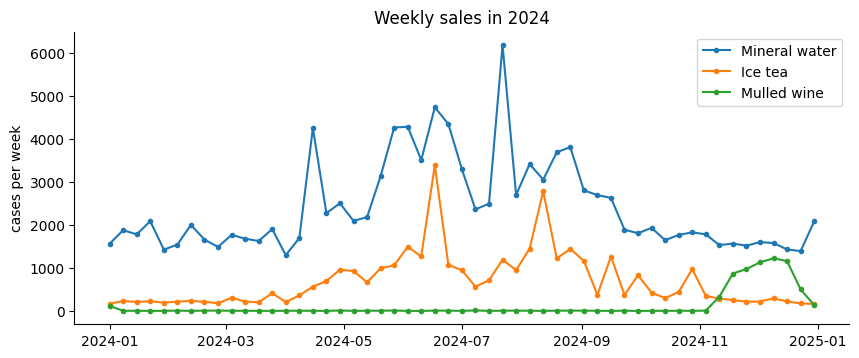

In [4]:
show = ["Mineral water", "Ice tea", "Mulled wine"]   # EDIT: any of the eight products
year = 2024                                         # EDIT: 2022 to 2025

fig, ax = plt.subplots(figsize=(10, 3.8))
for product in show:
    one = sales[(sales["product"] == product) & (sales["week_start"].dt.year == year)]
    ax.plot(one["week_start"], one["units"], marker="o", ms=3, label=product)
ax.set(title=f"Weekly sales in {year}", ylabel="cases per week")
ax.legend()
plt.show()

**What to see.** Water and ice tea peak in summer; mulled wine sells only in Advent and almost nothing the rest of the year. Each product follows its own conditions.

Now ice tea against the temperature forecast, in the two years we learn from (2023 and 2024). Each dot is one week.

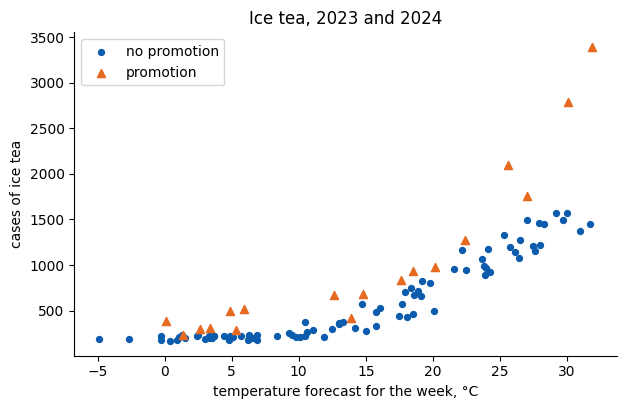

105 weeks, 18 of them with a promotion


In [5]:
ice = sales[(sales["product"] == "Ice tea") & (sales["week_start"].dt.year.between(2023, 2024))].copy()
promo = ice["discount_pct"] > 0

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(ice.loc[~promo, "temp_forecast"], ice.loc[~promo, "units"], s=18, color="#0B5CAD", label="no promotion")
ax.scatter(ice.loc[promo, "temp_forecast"], ice.loc[promo, "units"], s=34, marker="^", color="#E66A1F", label="promotion")
ax.set(xlabel="temperature forecast for the week, °C", ylabel="cases of ice tea", title="Ice tea, 2023 and 2024")
ax.legend()
plt.show()
print(len(ice), "weeks,", promo.sum(), "of them with a promotion")
# CHECK: 105 weeks, 18 of them with a promotion

**What to see.** Below about 15 °C ice tea hardly reacts to the weather. Above 20 °C it climbs steeply. The triangles, promotion weeks, sit higher, and much higher in warm weeks. Keep this curve in mind: it is the shape a straight line cannot follow.

## 3. The straight line from session 2

The same simple regression as in session 2: one input, one straight line, fitted with ordinary least squares (OLS).

> **Ask an AI** · *"With statsmodels formula API, fit an OLS regression of units on temp_forecast for the DataFrame ice, store it as line, and print the coefficients rounded to 1 decimal."*
> **Check:** the slope must be the `# CHECK` value; if the AI uses scikit-learn instead, the numbers are the same.

In [6]:
import statsmodels.formula.api as smf

line = smf.ols("units ~ temp_forecast", data=ice).fit()     # the simple regression of session 2
print(line.params.round(1))
print("The line at 0 °C: ", round(line.params["Intercept"]), "cases")
# CHECK: temp_forecast 49.2: one degree warmer, about 49 cases more, in January as in July
# CHECK: at 0 °C the line says -38 cases, fewer than nothing

Intercept       -37.8
temp_forecast    49.2
dtype: float64
The line at 0 °C:  -38 cases


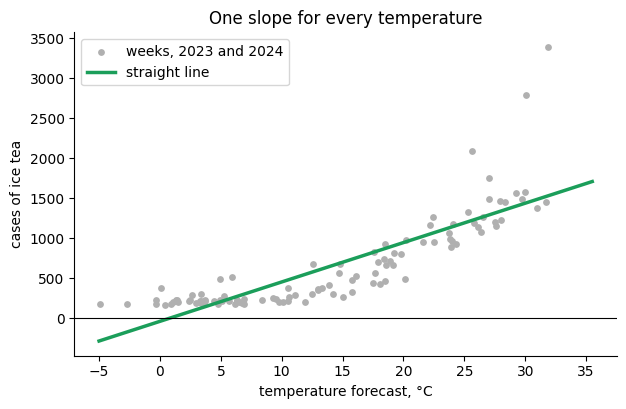

In [7]:
grid = pd.DataFrame({"temp_forecast": np.arange(-5, 36, 0.5), "discount_pct": 0})    # every temperature, no promotion

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(ice["temp_forecast"], ice["units"], s=15, color="#B0B0B0", label="weeks, 2023 and 2024")
ax.plot(grid["temp_forecast"], line.predict(grid), color=COLOURS["Linear regression"], lw=2.5, label="straight line")
ax.axhline(0, color="black", lw=0.8)
ax.set(xlabel="temperature forecast, °C", ylabel="cases of ice tea", title="One slope for every temperature")
ax.legend()
plt.show()

**What to see.** The line is too high between about 5 and 18 °C, too low in hot weeks, and below zero in frost. One slope for all temperatures is the problem: how much one more degree adds depends on how warm it already is.

## 4. Your first decision tree

A **decision tree** asks yes-or-no questions about the inputs, one after the other, for example *"Is the temperature forecast above 20 °C?"*. The answers lead down to a **leaf**, and every leaf predicts the **average of the training weeks** that ended there.

Two settings, called knobs from now on:

- `max_depth=2`: at most two questions in a row,
- `min_samples_leaf=5`: every leaf must hold at least 5 weeks, so no rule rests on one odd week.

> **Ask an AI** · *"Fit a scikit-learn DecisionTreeRegressor with max_depth=2, min_samples_leaf=5 and random_state=42 on the columns temp_forecast and discount_pct of ice, target units, and print its rules with export_text."*
> **Check:** the first question must be the one in the `# CHECK` line.

In [8]:
from sklearn.tree import DecisionTreeRegressor, export_text, plot_tree

inputs = ["temp_forecast", "discount_pct"]
tree = DecisionTreeRegressor(max_depth=2, min_samples_leaf=5, random_state=42)    # EDIT: try max_depth=3
tree.fit(ice[inputs], ice["units"])                       # learn the questions from 2023 and 2024
print(export_text(tree, feature_names=inputs))
# CHECK: the first question is temp_forecast <= 20.15; a warm week with a promotion: 2045.83 cases

|--- temp_forecast <= 20.15
|   |--- temp_forecast <= 14.45
|   |   |--- value: [259.17]
|   |--- temp_forecast >  14.45
|   |   |--- value: [607.40]
|--- temp_forecast >  20.15
|   |--- discount_pct <= 5.00
|   |   |--- value: [1222.24]
|   |--- discount_pct >  5.00
|   |   |--- value: [2045.83]



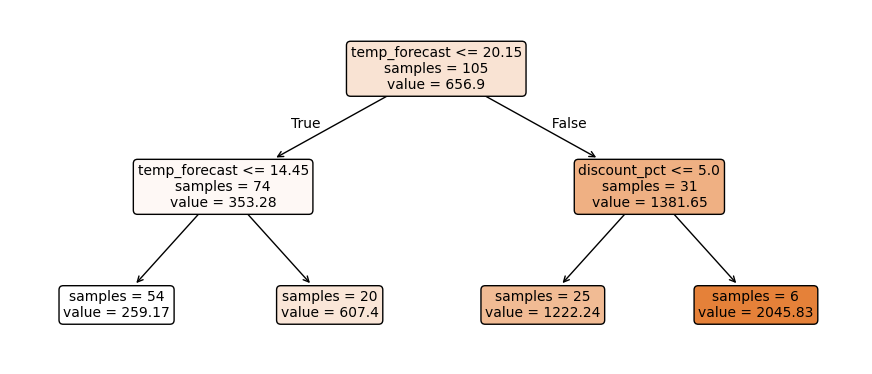

In [9]:
plt.figure(figsize=(11, 4.6))
plot_tree(tree, feature_names=inputs, filled=True, impurity=False, rounded=True, precision=2, fontsize=10)
plt.show()

**How to read it.** Start at the top. If the answer is yes (true), go left; if no, go right. `samples` is the number of training weeks in a box, `value` their average sales.

- A cool week (forecast 20.1 °C or less) splits once more by temperature: 259 or 607 cases.
- A warm week splits by the promotion: 1,222 cases without, 2,046 with one (`discount_pct <= 5` means no promotion).

**Notice:** the promotion question appears only on the warm side. In warm weeks the promotion makes the big difference; in cool weeks the temperature matters more. Nobody told the tree; it found the interaction in the data. Read any path as a rule: *if the forecast is above 20.15 °C and a promotion is planned, expect about 2,046 cases.*

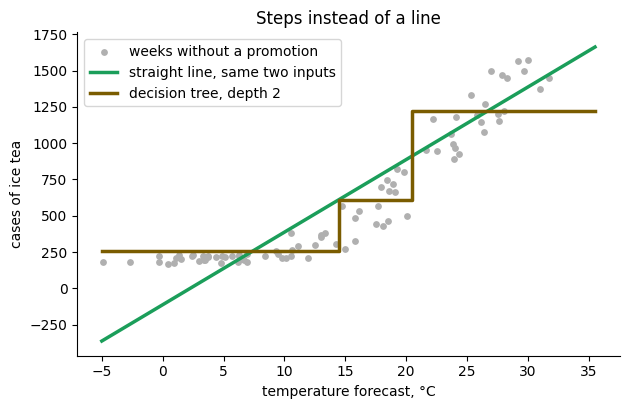

In [10]:
line2 = smf.ols("units ~ temp_forecast + discount_pct", data=ice).fit()      # the same two inputs as the tree
fig, ax = plt.subplots(figsize=(7, 4.2))
no_promo = ice[ice["discount_pct"] == 0]
ax.scatter(no_promo["temp_forecast"], no_promo["units"], s=15, color="#B0B0B0", label="weeks without a promotion")
ax.plot(grid["temp_forecast"], line2.predict(grid), color=COLOURS["Linear regression"], lw=2.5,
        label="straight line, same two inputs")
ax.plot(grid["temp_forecast"], tree.predict(grid[inputs]), color=COLOURS["Decision tree"], lw=2.5,
        drawstyle="steps-post", label="decision tree, depth 2")
ax.set(xlabel="temperature forecast, °C", ylabel="cases of ice tea", title="Steps instead of a line")
ax.legend()
plt.show()

**What to see.** Both models know the temperature and the promotion; here both are drawn for weeks without a promotion. The tree draws **steps**: flat, a jump, flat again. A tree forecasts averages of real weeks, so it never forecasts less than zero, while the line does. But it also never goes above its highest step: however hot it gets, the forecast stays where the hottest training weeks were. Remember this for later.

## 5. Learn, choose, test: three periods

A forecast must be judged on weeks the model has never seen, and every choice, such as the depth of a tree, must be made **without** looking at those weeks. So we use three periods:

| Period | What happens |
|---|---|
| 2023 | the tree learns |
| 2024 | we choose the depth: the **validation** year |
| 2025 | the final test, used once, after every choice is made |

Once the depth is chosen, the tree learns again from 2023 and 2024 together, and only then do we look at 2025.

**How we forecast:** one week at a time. Every Sunday evening we forecast the coming week with what is known that evening: the weather forecast, the promotion plan, the holidays. The final model is fitted on Sunday 5 January 2025, after the week that started on 30 December has finished (we assume its sales are final that evening), and then stays fixed. Two more inputs join now: the holidays and the week of the year (1 to 52 in our years).

Three numbers judge a forecast:

- **MAE**, the average miss, in cases: forecast 900, actual 1,000, miss 100.
- **WAPE**, all misses added up (too high and too low alike), divided by all cases actually sold: misses of 100 and 300 on sales of 1,000 and 3,000 give 400 ÷ 4,000 = 10 %. It is not a share of lost sales.
- **Bias**, forecast minus actual, on average: minus means the forecast was too low.

In [11]:
def score(actual, forecast):
    """Three numbers for a forecast. MAE: the average miss in cases. WAPE: all misses added up, as a
    percentage of all cases sold. Bias: forecast minus actual, on average (minus means too low)."""
    if isinstance(actual, pd.Series) and isinstance(forecast, pd.Series):
        assert actual.index.equals(forecast.index), "Actuals and forecasts must belong to the same weeks."
    a, f = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    assert a.ndim == 1 and a.size > 0 and a.shape == f.shape, "One forecast for every week, in one column."
    assert np.isfinite(a).all() and np.isfinite(f).all(), "Every week needs a number: no missing actual or forecast."
    miss, total = f - a, np.abs(a).sum()
    return pd.Series({"MAE, cases": np.abs(miss).mean(),
                      "WAPE, %": np.abs(miss).sum() / total * 100 if total else np.nan,   # undefined if nothing was sold
                      "Bias, cases": miss.mean()})

In [12]:
ice_all = sales[sales["product"] == "Ice tea"].sort_values("week_start").copy()
assert (ice_all["week_start"].diff().dropna() == pd.Timedelta(days=7)).all(), "A week is missing or doubled: shift(52) would not be 52 weeks back."
ice_all["week_of_year"] = ice_all["week_start"].dt.isocalendar().week.astype(int)
ice_all["same_week_last_year"] = ice_all["units"].shift(52)             # sales 52 weeks earlier
inputs = ["temp_forecast", "discount_pct", "holiday_days", "week_of_year"]

year = ice_all["week_start"].dt.year
learn, check, test = ice_all[year == 2023], ice_all[year == 2024], ice_all[year == 2025].copy()
print(len(learn), "weeks to learn,", len(check), "weeks to choose,", len(test), "weeks to test")
# CHECK: 52 weeks to learn, 53 weeks to choose, 52 weeks to test

52 weeks to learn, 53 weeks to choose, 52 weeks to test


**Choose the depth on 2024.** A deeper tree asks more questions and fits the weeks it learns from better. Does it also forecast new weeks better? We grow trees of depth 1 to 10, with nothing that stops them (no `min_samples_leaf`), learn from 2023, and score each on 2023 and on 2024.

> **Ask an AI** · *"For max_depth from 1 to 10, fit a DecisionTreeRegressor(random_state=42) on learn[inputs] and learn['units'], put the WAPE on learn and on check into one table and one line chart, and print the depth with the lowest WAPE on check."*
> **Check:** the depth it prints must be the one in the `# CHECK` line; the AI must never use `test` here.

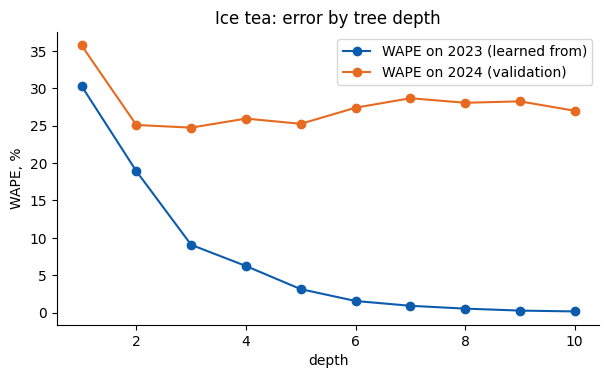

The depth with the lowest error on 2024: 3


,WAPE on 2023 (learned from),WAPE on 2024 (validation)
depth,,
1,30.3,35.7
2,18.9,25.1
3,9.1,24.7
4,6.2,26.0
5,3.1,25.3
6,1.6,27.4
7,0.9,28.7
8,0.5,28.1
9,0.3,28.3


In [13]:
rows = []
for depth in range(1, 11):
    t = DecisionTreeRegressor(max_depth=depth, random_state=42).fit(learn[inputs], learn["units"])
    rows.append({"depth": depth,
                 "WAPE on 2023 (learned from)": score(learn["units"], t.predict(learn[inputs]))["WAPE, %"],
                 "WAPE on 2024 (validation)": score(check["units"], t.predict(check[inputs]))["WAPE, %"]})
depths = pd.DataFrame(rows).set_index("depth")
best_depth = int(depths["WAPE on 2024 (validation)"].idxmin())
depths.plot(marker="o", figsize=(7, 3.8), color=["#0B5CAD", "#E66A1F"], ylabel="WAPE, %",
            title="Ice tea: error by tree depth")
plt.show()
print("The depth with the lowest error on 2024:", best_depth)
depths.round(1)
# CHECK: the depth with the lowest error on 2024: 3 (24.7 %); on 2023 the error falls to 0.2 % at depth 10

**What to see.** On the weeks it learned from, the error falls towards zero: a deep tree memorises 2023, odd weeks included (with this data it falls at every step, but that is not guaranteed). On 2024 the error is lowest at depth 3; more depth does not help any more. That is **overfitting**: the tree learns the noise of 2023 instead of the pattern. We choose depth 3, and we have not looked at 2025 yet.

## 6. The final test on 2025

The tree with the chosen depth learns again, from 2023 and 2024, and forecasts every week of 2025. Next to it: the straight line with the same four inputs, and the benchmark, which repeats last year (the sales 52 weeks earlier).

In [14]:
train = ice_all[year.isin([2023, 2024])]                                  # learn again, from both years
test["Repeat last year"] = test["same_week_last_year"]                     # the benchmark
reg = smf.ols("units ~ temp_forecast + discount_pct + holiday_days + week_of_year", data=train).fit()
test["Linear regression"] = reg.predict(test)
final_tree = DecisionTreeRegressor(max_depth=best_depth, random_state=42).fit(train[inputs], train["units"])
test["Decision tree"] = final_tree.predict(test[inputs])

methods = ["Repeat last year", "Linear regression", "Decision tree"]
pd.DataFrame({m: score(test["units"], test[m]) for m in methods}).T
# CHECK: WAPE 49.2 %, 34.1 % and 23.5 %

,"MAE, cases","WAPE, %","Bias, cases"
Repeat last year,332.4,49.2,22.3
Linear regression,229.9,34.1,30.1
Decision tree,158.9,23.5,12.4


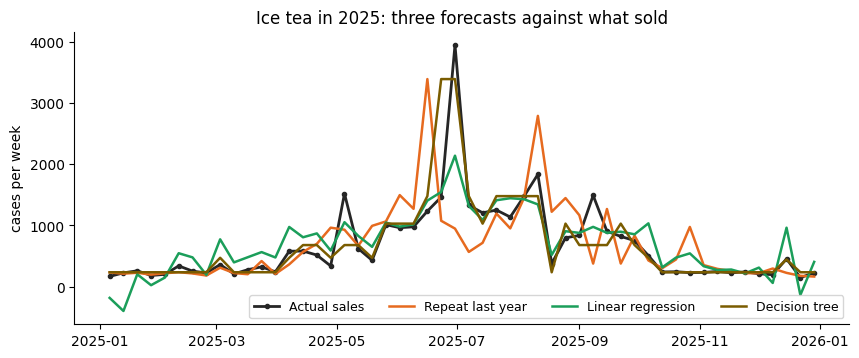

In [15]:
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(test["week_start"], test["units"], color=COLOURS["Actual sales"], lw=2, marker="o", ms=3, label="Actual sales")
for m in methods:
    ax.plot(test["week_start"], test[m], color=COLOURS[m], lw=1.8, label=m)
ax.set(title="Ice tea in 2025: three forecasts against what sold", ylabel="cases per week")
ax.legend(ncol=4, fontsize=9)
plt.show()

**What to see.** Repeating last year copies last summer's weather into this summer. The straight line misses the peaks and runs too high in winter. The tree follows the summer much better, with the steps you saw before. In our data, on this product, the tree wins; whether it wins on yours, only such a test can tell.

### Your answer (not graded; it prepares your project)

1. Read one rule from your depth-2 tree in section 4: *in a week warmer than ___ °C with a promotion, the tree expects about ___ cases.*
2. Which depth gives the lowest error on 2024? ___ Why do we choose the depth on 2024 and not on 2025? ___
3. In one sentence: why can the tree follow the ice tea curve better than the straight line?

**Next:** one tree is easy to read but rough. In notebook 2 many trees work together, for all eight products at once.